
# IMPORT REQUIRED LIBRARIES



In [28]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
from debugpy.adapter.components import missing
from pyspark.sql.connect.functions import upper

# Read CSV file and check the first 5 rows


In [29]:
df = pd.read_csv('Melbourne_housing.csv')

df.head()

C:\Users\maimu\AppData\Local\Temp\ipykernel_20840\2654485170.py:1: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Melbourne_housing.csv')


,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Abbotsford,68 Studley St,2,h,SS,Jellis,3/9/2016,2.5,3067.0,2.0,...,126.0,inf,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0,Carport,NaN
1,Airport West,154 Halsey Rd,3,t,PI,Nelson,3/9/2016,13.5,3042.0,3.0,...,303.0,225,2016.0,Moonee Valley City Council,-37.7180,144.8780,Western Metropolitan,3464.0,Detached Garage,840000.0
2,Albert Park,105 Kerferd Rd,2,h,S,hockingstuart,3/9/2016,3.3,3206.0,2.0,...,120.0,82,1900.0,Port Phillip City Council,-37.8459,144.9555,Southern Metropolitan,3280.0,Attached Garage,1275000.0
3,Albert Park,85 Richardson St,2,h,S,Thomson,3/9/2016,3.3,3206.0,2.0,...,159.0,inf,NaN,Port Phillip City Council,-37.8450,144.9538,Southern Metropolitan,3280.0,Indoor,1455000.0
4,Alphington,30 Austin St,3,h,SN,McGrath,3/9/2016,6.4,3078.0,3.0,...,174.0,122,2003.0,Darebin City Council,-37.7818,145.0198,Northern Metropolitan,2211.0,Parkade,NaN


# The dataset is heavily skewed toward metro regions, while rural regions are rare (<1% of data). Random sampling 5,000 rows preserves the overall distribution of major regions and general price trends. Rare regions may have very few rows, so predictions for them might be less reliable, but this reflects the original dataset and does not indicate a sampling error. Therefore, random sampling is appropriate for general house price regression

In [65]:
categorical_cols = ['Type', 'Method', 'Regionname', 'CouncilArea']

for col in categorical_cols:
    counts = df[col].value_counts(normalize=True)  # proportions
    print(f"{col} distribution:\n{counts}\n")


Type distribution:
Type
h    0.687954
u    0.209341
t    0.102705
Name: proportion, dtype: float64

Method distribution:
Method
S     0.566429
SP    0.146169
PI    0.139140
VB    0.089164
SN    0.037783
PN    0.008836
SA    0.006484
W     0.004963
SS    0.001033
Name: proportion, dtype: float64

Regionname distribution:
Regionname
Southern Metropolitan         0.339559
Northern Metropolitan         0.274263
Western Metropolitan          0.195054
Eastern Metropolitan          0.125570
South-Eastern Metropolitan    0.049890
Eastern Victoria              0.006541
Northern Victoria             0.005824
Western Victoria              0.003299
Name: proportion, dtype: float64

CouncilArea distribution:
CouncilArea
Boroondara City Council           0.105440
Darebin City Council              0.081798
Moreland City Council             0.060883
Glen Eira City Council            0.057554
Melbourne City Council            0.056005
Banyule City Council              0.053394
Moonee Valley City Counci

In [66]:
region_counts = df['Regionname'].value_counts(normalize=True)
print(region_counts)


Regionname
Southern Metropolitan         0.339559
Northern Metropolitan         0.274263
Western Metropolitan          0.195054
Eastern Metropolitan          0.125570
South-Eastern Metropolitan    0.049890
Eastern Victoria              0.006541
Northern Victoria             0.005824
Western Victoria              0.003299
Name: proportion, dtype: float64


# reducing the dataset to 5000 since it big

In [30]:
sample_df = df.sample(n=5000, random_state=42)
print(sample_df.shape)


(5000, 22)


In [67]:
region_counts = sample_df['Regionname'].value_counts(normalize=True)
print(region_counts)


Regionname
Southern Metropolitan         0.308601
Northern Metropolitan         0.284211
Western Metropolitan          0.227985
Eastern Metropolitan          0.116560
South-Eastern Metropolitan    0.048780
Northern Victoria             0.005905
Eastern Victoria              0.005905
Western Victoria              0.002054
Name: proportion, dtype: float64


# check last 5 rows to understand the data 

In [31]:
sample_df.tail()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
26332,Kingsbury,1/30 Keats Av,3,u,S,Barry,24/02/2018,12.1,3083.0,NaN,...,NaN,NaN,NaN,Darebin City Council,NaN,NaN,Northern Metropolitan,1414.0,Detached Garage,643000.0
9558,Sydenham,28 Albertine Cr,4,h,W,Prof.,9/12/2017,18.0,3037.0,4.0,...,557.0,NaN,NaN,Brimbank City Council,-37.71039,144.77957,Western Metropolitan,3640.0,Underground,NaN
4097,Brighton,160 Were St,5,h,SP,Hodges,1/7/2017,10.5,3186.0,5.0,...,835.0,NaN,NaN,Bayside City Council,-37.92615,145.00282,Southern Metropolitan,10579.0,Attached Garage,3250000.0
29219,Ascot Vale,37 Epsom Rd,3,h,SP,Frank,26/07/2016,5.9,3032.0,3.0,...,536.0,NaN,NaN,Moonee Valley City Council,-37.77280,144.90760,Western Metropolitan,6567.0,Parking Pad,1050000.0
19377,Box Hill,33 Pendle St,4,h,S,Noel,17/09/2016,13.1,3128.0,4.0,...,707.0,162,1926.0,Whitehorse City Council,-37.81660,145.13540,Eastern Metropolitan,4605.0,Carport,1670000.0


In [32]:
sample_df.describe()

,Rooms,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,YearBuilt,Latitude,Longtitude,Propertycount,Price
count,5000.000000,5000.000000,5000.000000,3844.000000,3843.000000,3767.000000,3308.000000,2256.000000,3879.000000,3879.000000,5000.000000,3.895000e+03
mean,3.014200,11.078200,3113.478200,3.059834,1.594588,1.715954,548.218259,1964.761525,-37.809071,144.998170,7688.005200,1.042889e+06
std,0.960303,6.729244,104.388477,0.945323,0.699216,0.975547,1235.013060,36.642818,0.090983,0.118023,4419.683293,6.357164e+05
min,1.000000,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,1820.000000,-38.182550,144.490000,249.000000,8.500000e+04
25%,2.000000,6.400000,3046.000000,2.000000,1.000000,1.000000,223.750000,1940.000000,-37.862100,144.928440,4442.000000,6.300000e+05
50%,3.000000,10.200000,3101.000000,3.000000,1.000000,2.000000,517.000000,1970.000000,-37.806720,145.003800,6795.000000,8.600000e+05
75%,4.000000,13.900000,3151.000000,4.000000,2.000000,2.000000,661.000000,1998.250000,-37.752680,145.067255,10412.000000,1.280000e+06
max,9.000000,47.400000,3977.000000,8.000000,7.000000,8.000000,41400.000000,2017.000000,-37.397800,145.412880,21650.000000,7.000000e+06


# checking the dtypes of the columns 

In [33]:
sample_df.dtypes

Suburb            object
Address           object
Rooms              int64
Type              object
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom          float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea      object
YearBuilt        float64
CouncilArea       object
Latitude         float64
Longtitude       float64
Regionname        object
Propertycount    float64
ParkingArea       object
Price            float64
dtype: object

# Checking the number of nulls values per column

In [34]:
#get the number of missing data points per column

missing_values_count = sample_df.isnull().sum()

# look at the # of missing points in the first 10 columns
missing_values_count[0:20]

Suburb              0
Address             0
Rooms               0
Type                0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom          1156
Bathroom         1157
Car              1233
Landsize         1692
BuildingArea     2999
YearBuilt        2744
CouncilArea         0
Latitude         1121
Longtitude       1121
Regionname          0
Propertycount       0
dtype: int64

# we want to see the percentage of our dataset that where missing to get better insight of the data

In [35]:
# how many total missing values do we have?

total_cells = np.prod(sample_df.shape)
total_missing = missing_values_count.sum()
# percent of data that is missing
percent_missing = (total_missing/total_cells) * 100
print(percent_missing)

13.025454545454545


In [37]:

# Count missing values
missing_count = sample_df.isnull().sum()

# Percentage missing
missing_percent = (missing_count / len(sample_df)) * 100

# Create a summary dataframe
missing_summary = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percent': missing_percent
})

# Recommend action based on missing %
def recommend_action(missing_percent, feature):
    if missing_percent == 0:
        return 'Keep as-is'
    elif missing_percent < 1:
        return 'Drop row or fill with mode/median'
    elif missing_percent < 20:
        return 'Impute with median or predictive model'
    else:
        return 'Consider impute with median + missing flag or drop if not critical'

missing_summary['Recommended_Action'] = missing_summary['Missing_Percent'].apply(lambda x: recommend_action(x, x))

# Sort by missing %
missing_summary = missing_summary.sort_values(by='Missing_Percent', ascending=False)

# Display
missing_summary


,Missing_Count,Missing_Percent,Recommended_Action
BuildingArea,2999,59.98,Consider impute with median + missing flag or ...
YearBuilt,2744,54.88,Consider impute with median + missing flag or ...
Landsize,1692,33.84,Consider impute with median + missing flag or ...
Car,1233,24.66,Consider impute with median + missing flag or ...
Bathroom,1157,23.14,Consider impute with median + missing flag or ...
Bedroom,1156,23.12,Consider impute with median + missing flag or ...
Latitude,1121,22.42,Consider impute with median + missing flag or ...
Longtitude,1121,22.42,Consider impute with median + missing flag or ...
Price,1105,22.10,Consider impute with median + missing flag or ...
Method,0,0.00,Keep as-is


## droping columns that contain more than 50% null

In [38]:
sample_df.drop(columns=['BuildingArea', 'YearBuilt'], inplace=True)


# checking if the columns are drop
sample_df.head()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
10953,Northcote,303/231 St Georges Rd,2,u,S,McGrath,12/8/2017,5.3,3070.0,NaN,NaN,NaN,NaN,Darebin City Council,NaN,NaN,Northern Metropolitan,11364.0,Detached Garage,673000.0
29454,Bentleigh East,63 Barrington St,3,h,S,Jellis,26/08/2017,13.8,3165.0,3.0,1.0,2.0,NaN,Glen Eira City Council,-37.91297,145.07350,Southern Metropolitan,10969.0,Attached Garage,1372500.0
21866,Maribyrnong,3/50 Middle Rd,1,u,PI,Brad,19/08/2017,4.3,3032.0,1.0,1.0,1.0,NaN,Maribyrnong City Council,-37.76722,144.88987,Western Metropolitan,4918.0,Underground,NaN
5673,Reservoir,39 Crevelli St,3,h,S,Stockdale,3/9/2017,12.0,3073.0,3.0,1.0,1.0,170.0,Darebin City Council,-37.72924,145.02981,Northern Metropolitan,21650.0,Outdoor Stall,612500.0
22924,Jacana,53 Lorraine Cr,3,h,S,YPA,20/05/2017,14.5,3047.0,NaN,NaN,NaN,NaN,Hume City Council,NaN,NaN,Northern Metropolitan,851.0,Attached Garage,515000.0


# checking if they are drop

In [39]:
sample_df.isnull().sum()

Suburb              0
Address             0
Rooms               0
Type                0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom          1156
Bathroom         1157
Car              1233
Landsize         1692
CouncilArea         0
Latitude         1121
Longtitude       1121
Regionname          0
Propertycount       0
ParkingArea         0
Price            1105
dtype: int64

# median preferable if data is skewed
replace null with mode for categorical data
replace missing values with mean or median if column for numerical data
if large nr of missing values these methods could skew

# Handling missing values:
# 1. Drop rows where 'Price' is missing, since this is the target variable and imputing it 
#    could introduce bias in the model.
# 2. For numerical features that are often skewed (Bedroom, Bathroom, Car, Landsize),
#    replace missing values with the median, which is more robust to outliers.
# 3. For geographical features (Latitude, Longtitude), replace missing values with the mean,
#    since these variables are not strongly skewed and the mean better preserves location trends.


In [16]:
#checking the skewness of each feature

print(sample_df['Bedroom'].skew())
print(sample_df['Price'].skew())
print(sample_df['Bathroom'].skew())
print(sample_df['Landsize'].skew())
print(sample_df['Car'].skew())
print(sample_df['Longtitude'].skew())
print(sample_df['Latitude'].skew())



0.24677499055390628
2.4167404658038074
1.0959170699041885
23.60624809479969
1.1607853262819008
-0.33994399577914935
-0.19744060748801887


# replacing nulls with the appropiate methods from the lectures

In [40]:
# Handle missing values based on skewness analysis

# 1. Drop rows where Price is missing (target variable) 
#    because imputing would bias the model
sample_df = sample_df.dropna(subset=['Price'])

# Fill Bedroom (skewness ~0.25, nearly symmetric) -> mean
sample_df['Bedroom'] = sample_df['Bedroom'].fillna(sample_df['Bedroom'].mean())

# Fill Bathroom (skewness 1.10) -> median
sample_df['Bathroom'] = sample_df['Bathroom'].fillna(sample_df['Bathroom'].median())

# Fill Landsize (skewness 23.6) -> median
sample_df['Landsize'] = sample_df['Landsize'].fillna(sample_df['Landsize'].median())

# Fill Car (skewness 1.16) -> median
sample_df['Car'] = sample_df['Car'].fillna(sample_df['Car'].median())

# Fill Latitude and Longtitude (not strongly skewed) -> mean
sample_df['Latitude'] = sample_df['Latitude'].fillna(sample_df['Latitude'].mean())

sample_df['Longtitude'] = sample_df['Longtitude'].fillna(sample_df['Longtitude'].mean())


In [41]:
# checking if the nulls are remove

sample_df.isnull().sum()

Suburb           0
Address          0
Rooms            0
Type             0
Method           0
SellerG          0
Date             0
Distance         0
Postcode         0
Bedroom          0
Bathroom         0
Car              0
Landsize         0
CouncilArea      0
Latitude         0
Longtitude       0
Regionname       0
Propertycount    0
ParkingArea      0
Price            0
dtype: int64

# Doing ANALYSIS ON THE TARGET VARIABLE USING HISTOGRAM


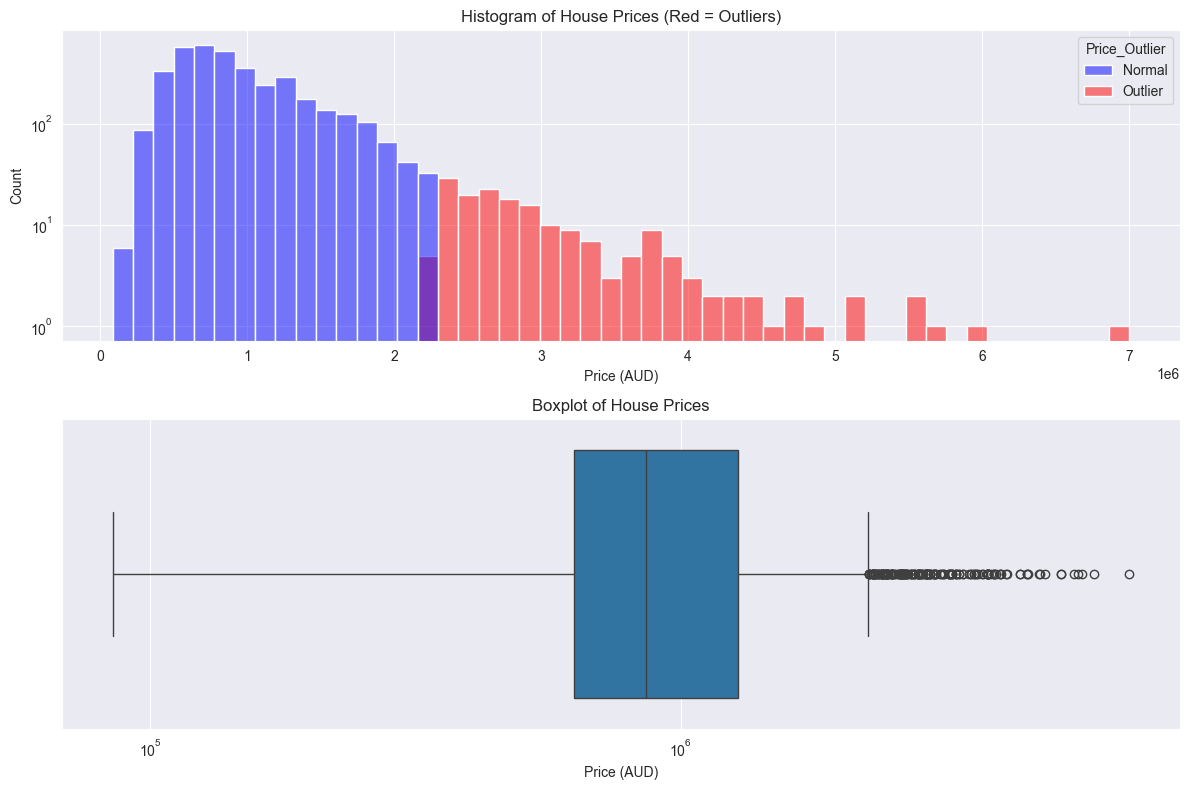

Rooms             0.295477
Distance          1.460687
Postcode          3.933717
Bedroom           0.273253
Bathroom          1.537199
Car               1.111266
Landsize         27.881094
Latitude         -0.285021
Longtitude       -0.356991
Propertycount     0.915845
Price             2.416740
dtype: float64


In [53]:
# Step 1: Create figure with two subplots
# -----------------------------
fig, axs = plt.subplots(2, 1, figsize=(12, 8))

# Histogram
sns.histplot(data=sample_df, x='Price', hue='Price_Outlier', palette={'Normal':'blue','Outlier':'red'}, bins=50, ax=axs[0])
axs[0].set_title('Histogram of House Prices (Red = Outliers)')
axs[0].set_xlabel('Price (AUD)')
axs[0].set_ylabel('Count')
axs[0].set_yscale('log')  # optional, to better visualize high counts

# Boxplot
sns.boxplot(data=sample_df, x='Price', ax=axs[1])
axs[1].set_title('Boxplot of House Prices')
axs[1].set_xlabel('Price (AUD)')
axs[1].set_xscale('log')  # optional, handles extreme high values

plt.tight_layout()
plt.show()

# Skewness of numeric columns
print(sample_df.skew(numeric_only=True))



# determining if there are outliers using IQR

In [44]:
Q1 = sample_df['Price'].quantile(0.25)
Q3 = sample_df['Price'].quantile(0.75)

IQR = abs(Q3 - Q1)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered_df = sample_df[(sample_df['Price'] < lower_bound) | (sample_df['Price'] > upper_bound)]

filtered_df

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
34238,Eaglemont,18 Carlsberg Rd,4,h,S,Miles,29/07/2017,8.9,3084.0,4.000000,2.0,3.0,1783.0,Banyule City Council,-37.764570,145.065550,Eastern Metropolitan,1651.0,Detached Garage,3300000.0
27905,Caulfield North,127 Normanby Rd,4,h,S,Marshall,25/02/2017,8.1,3161.0,4.000000,2.0,3.0,836.0,Glen Eira City Council,-37.869600,145.032300,Southern Metropolitan,6923.0,Attached Garage,2625000.0
34562,Yarraville,54 Pentland Pde,6,h,VB,Village,29/07/2017,6.3,3013.0,6.000000,3.0,2.0,1087.0,Maribyrnong City Council,-37.810380,144.893890,Western Metropolitan,6543.0,Attached Garage,2450000.0
30351,Fitzroy,49/183 Kerr St,3,u,S,Nelson,27/05/2017,2.1,3065.0,3.029058,1.0,2.0,515.0,Yarra City Council,-37.806498,144.992667,Northern Metropolitan,5825.0,Carport,2265000.0
21069,Hawthorn East,8 Campbell Gr,5,h,S,Kay,18/11/2017,6.2,3123.0,5.000000,3.0,2.0,515.0,Boroondara City Council,-37.833500,145.048400,Southern Metropolitan,6482.0,Carport,3525500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29238,Brighton,9 Laburnum St,4,h,VB,Buxton,26/07/2016,11.2,3186.0,3.029058,1.0,2.0,515.0,Bayside City Council,-37.806498,144.992667,Southern Metropolitan,10579.0,Carport,2900000.0
18195,Hawthorn East,41 Leura Gr,4,h,S,Kay,17/03/2018,6.2,3123.0,4.000000,2.0,2.0,667.0,Boroondara City Council,-37.837380,145.051060,Southern Metropolitan,6482.0,Attached Garage,3575000.0
20957,Essendon,20 McCarron Pde,4,h,VB,Nelson,18/11/2017,7.5,3040.0,4.000000,3.0,2.0,515.0,Moonee Valley City Council,-37.751800,144.905700,Western Metropolitan,9264.0,Indoor,2600000.0
9682,Canterbury,29 Rubens Gr,4,h,PI,Marshall,11/2/2017,9.0,3126.0,4.000000,1.0,1.0,858.0,Boroondara City Council,-37.818300,145.066700,Southern Metropolitan,3265.0,Indoor,3800000.0


In [50]:
# Check the top 10 highest price outliers
filtered_df.sort_values(by='Price', ascending=False).head(10)

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
28325,Armadale,1 Barnato Gr,4,h,PI,Kay,25/11/2017,6.3,3143.0,3.029058,1.0,2.0,515.0,Stonnington City Council,-37.806498,144.992667,Southern Metropolitan,4836.0,Detached Garage,7000000.0
17933,Camberwell,15 Victoria Rd,5,h,VB,Marshall,17/03/2018,7.7,3124.0,5.000000,3.0,4.0,1338.0,Boroondara City Council,-37.823590,145.060340,Southern Metropolitan,8920.0,Underground,6000000.0
3942,South Yarra,18 Avoca St,4,h,S,Castran,12/11/2016,3.3,3141.0,4.000000,2.0,0.0,292.0,Melbourne City Council,-37.837700,144.989400,Southern Metropolitan,14887.0,Detached Garage,5700000.0
4955,Middle Park,204 Page St,6,h,PI,Marshall,3/6/2017,3.0,3206.0,6.000000,4.0,2.0,472.0,Port Phillip City Council,-37.852310,144.963730,Southern Metropolitan,2019.0,Underground,5600000.0
733,Toorak,10 Myoora Rd,4,h,VB,Marshall,3/12/2016,4.6,3142.0,4.000000,3.0,2.0,691.0,Stonnington City Council,-37.843100,145.021000,Southern Metropolitan,7217.0,Parkade,5500000.0
4061,Armadale,52 Adelaide St,5,h,SP,Marshall,1/7/2017,6.3,3143.0,5.000000,3.0,3.0,761.0,Stonnington City Council,-37.853110,145.028470,Southern Metropolitan,4836.0,Attached Garage,5200000.0
9235,Kew,8 Adeney Av,6,h,VB,Marshall,9/12/2017,5.4,3101.0,6.000000,2.0,2.0,1642.0,Boroondara City Council,-37.807550,145.048100,Southern Metropolitan,10331.0,Detached Garage,5200000.0
3820,Kew,23 Grange Rd,5,h,S,Caine,12/11/2016,5.6,3101.0,5.000000,4.0,4.0,957.0,Boroondara City Council,-37.811200,145.057000,Southern Metropolitan,10331.0,Detached Garage,4850000.0
30208,Canterbury,42 Parlington St,4,h,S,Kay,27/05/2017,8.4,3126.0,4.000000,3.0,2.0,967.0,Boroondara City Council,-37.817920,145.062440,Southern Metropolitan,3265.0,Indoor,4750000.0
27757,Albert Park,115 Page St,4,h,S,Marshall,25/02/2017,3.3,3206.0,4.000000,2.0,1.0,330.0,Port Phillip City Council,-37.847700,144.955800,Southern Metropolitan,3280.0,Carport,4735000.0


In [48]:


# Check the top 10 lowest price outliers
filtered_df.sort_values(by='Price', ascending=True).head(10)


,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
1791,South Melbourne,352 Moray St,4,h,PI,Marshall,7/5/2016,2.1,3205.0,5.000000,3.0,0.0,190.0,Port Phillip City Council,-37.837700,144.965300,Southern Metropolitan,5943.0,Indoor,2260000.0
512,Glen Iris,28 Malvern Av,3,h,S,J,3/12/2016,9.2,3146.0,3.029058,1.0,2.0,515.0,Boroondara City Council,-37.806498,144.992667,Southern Metropolitan,10412.0,Parkade,2260000.0
23006,Beaumaris,37 Deauville St,4,h,S,Marshall,21/10/2017,17.3,3193.0,4.000000,2.0,2.0,515.0,Bayside City Council,-37.984100,145.047750,Southern Metropolitan,5366.0,Outdoor Stall,2260000.0
30351,Fitzroy,49/183 Kerr St,3,u,S,Nelson,27/05/2017,2.1,3065.0,3.029058,1.0,2.0,515.0,Yarra City Council,-37.806498,144.992667,Northern Metropolitan,5825.0,Carport,2265000.0
23542,Surrey Hills,14 Grovedale Rd,4,h,S,Lindellas,21/10/2017,10.2,3127.0,4.000000,2.0,2.0,627.0,Boroondara City Council,-37.815820,145.094430,Southern Metropolitan,5457.0,Outdoor Stall,2285000.0
33573,South Yarra,90 River St,3,h,SP,Marshall,28/10/2017,2.7,3141.0,3.000000,2.0,2.0,211.0,Melbourne City Council,-37.836290,144.997980,Southern Metropolitan,14887.0,Outdoor Stall,2300000.0
25697,South Yarra,203/8 Murphy St,3,u,VB,Kay,23/09/2017,2.7,3141.0,3.029058,1.0,2.0,515.0,Melbourne City Council,-37.806498,144.992667,Southern Metropolitan,14887.0,Carport,2300000.0
34673,Malvern,31a Winter St,3,h,S,Jellis,30/07/2016,7.4,3144.0,3.000000,2.0,2.0,313.0,Stonnington City Council,-37.860300,145.032200,Southern Metropolitan,4675.0,Indoor,2300000.0
23430,Port Melbourne,273 Ross St,4,h,S,Marshall,21/10/2017,3.5,3207.0,4.000000,3.0,1.0,515.0,Melbourne City Council,-37.832810,144.941560,Southern Metropolitan,8648.0,Detached Garage,2300000.0
27653,South Melbourne,372 Dorcas St,3,h,S,RT,24/09/2016,2.1,3205.0,3.000000,2.0,2.0,0.0,Port Phillip City Council,-37.835200,144.952000,Southern Metropolitan,5943.0,Indoor,2300000.0


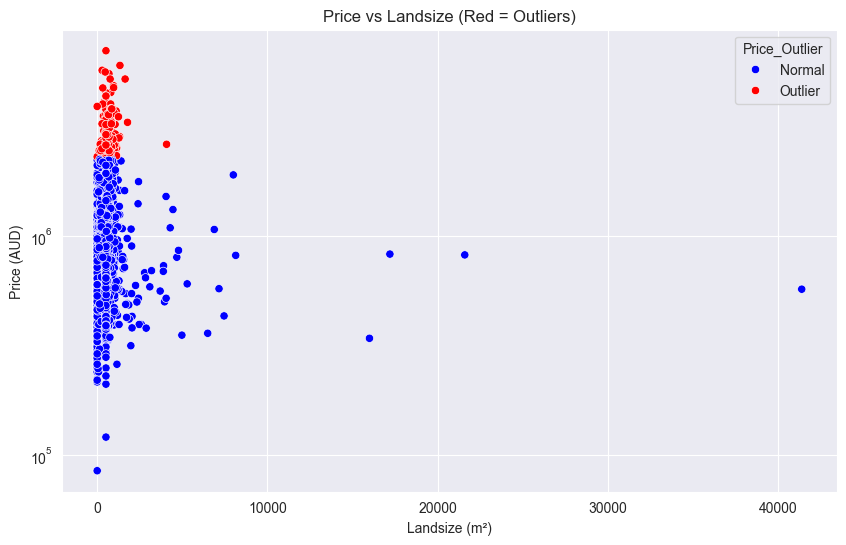

In [49]:
# Define bounds for outliers (IQR method)
Q1 = sample_df['Price'].quantile(0.25)
Q3 = sample_df['Price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag rows as outlier or not
sample_df['Price_Outlier'] = sample_df['Price'].apply(
    lambda x: 'Outlier' if x < lower_bound or x > upper_bound else 'Normal'
)

# Scatter plot
plt.figure(figsize=(10,6))
sns.scatterplot(data=sample_df, x='Landsize', y='Price', hue='Price_Outlier', palette={'Normal':'blue','Outlier':'red'})
plt.title('Price vs Landsize (Red = Outliers)')
plt.xlabel('Landsize (m²)')
plt.ylabel('Price (AUD)')
plt.yscale('log')  # optional, makes high prices easier to visualize
plt.show()

# “The Price column is highly positively skewed due to a few very expensive houses. To reduce skewness and stabilize variance, I applied a log transformation to Price. This compresses extreme high values, spreads out smaller values, and makes the data distribution more suitable for modeling and analysis.”

In [54]:
import numpy as np

# Create a new column for log-transformed price
sample_df['LogPrice'] = np.log(sample_df['Price'])

# Check the skewness after transformation
print("Skewness of original Price:", sample_df['Price'].skew())
print("Skewness of log-transformed Price:", sample_df['LogPrice'].skew())


Skewness of original Price: 2.416740465803807
Skewness of log-transformed Price: 0.32914624103407664


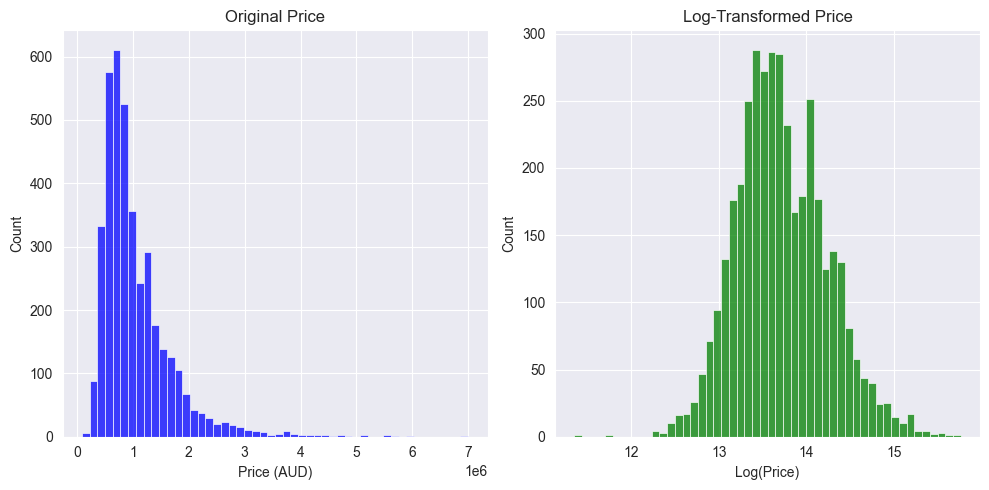

In [55]:
plt.figure(figsize=(10,5))

# Histogram of original Price
plt.subplot(1,2,1)
sns.histplot(sample_df['Price'], bins=50, color='blue')
plt.title('Original Price')
plt.xlabel('Price (AUD)')

# Histogram of log-transformed Price
plt.subplot(1,2,2)
sns.histplot(sample_df['LogPrice'], bins=50, color='green')
plt.title('Log-Transformed Price')
plt.xlabel('Log(Price)')

plt.tight_layout()
plt.show()

<Axes: xlabel='Landsize', ylabel='Count'>

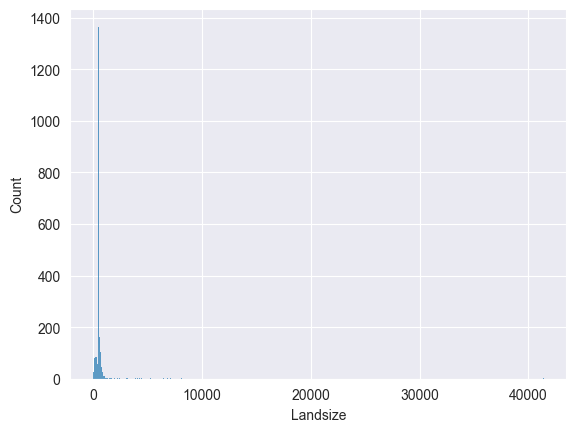

Numeric columns: ['Rooms', 'Distance', 'Postcode', 'Bedroom', 'Bathroom', 'Car', 'Landsize', 'Latitude', 'Longtitude', 'Propertycount', 'Price', 'LogPrice']


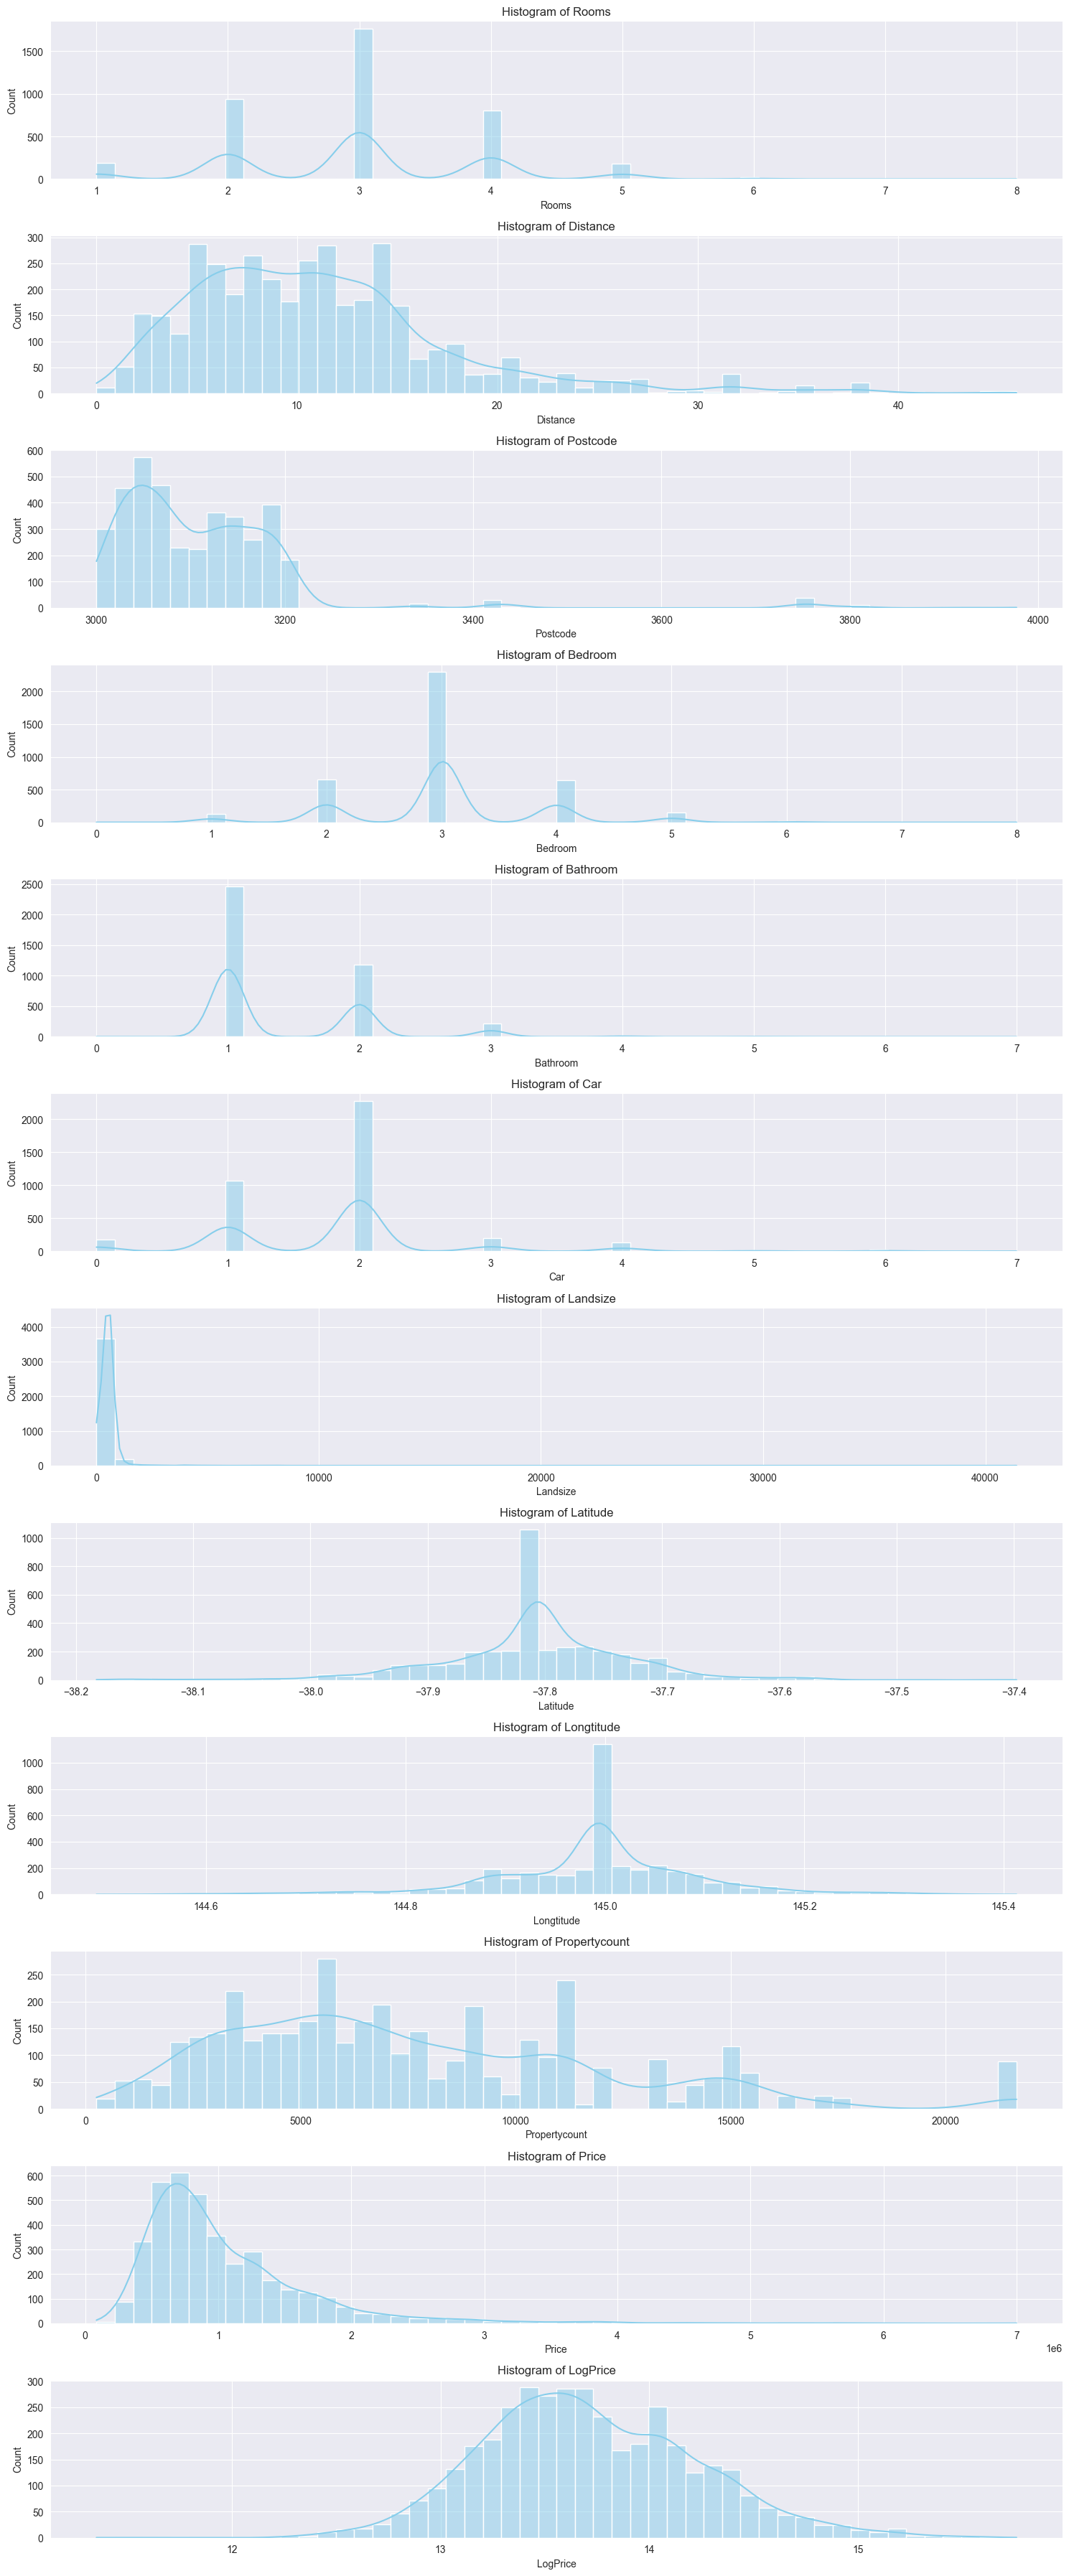

Skewness for numeric columns:
Rooms             0.295477
Distance          1.460687
Postcode          3.933717
Bedroom           0.273253
Bathroom          1.537199
Car               1.111266
Landsize         27.881094
Latitude         -0.285021
Longtitude       -0.356991
Propertycount     0.915845
Price             2.416740
LogPrice          0.329146
dtype: float64

Rooms has 3 outliers

Distance has 166 outliers
Consider log-transform or capping for Distance

Postcode has 107 outliers
Consider log-transform or capping for Postcode

Bedroom has 1597 outliers

Bathroom has 29 outliers
Consider log-transform or capping for Bathroom

Car has 170 outliers
Consider log-transform or capping for Car

Landsize has 137 outliers
Consider log-transform or capping for Landsize

Latitude has 250 outliers

Longtitude has 277 outliers

Propertycount has 89 outliers

Price has 179 outliers
Consider log-transform or capping for Price

LogPrice has 37 outliers


In [58]:
# List numeric columns
numeric_cols = sample_df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_cols)

# -----------------------------
# Step 1: Plot histogram for each numeric variable
# -----------------------------
plt.figure(figsize=(15, len(numeric_cols)*3))

for i, col in enumerate(numeric_cols):
    plt.subplot(len(numeric_cols), 1, i+1)
    sns.histplot(sample_df[col], bins=50, kde=True, color='skyblue')
    plt.title(f'Histogram of {col}')
plt.tight_layout()
plt.show()

# -----------------------------
# Step 2: Check skewness
# -----------------------------
skewness = sample_df[numeric_cols].skew()
print("Skewness for numeric columns:")
print(skewness)

# -----------------------------
# Step 3: Handle outliers if necessary
# -----------------------------
# Example: Using IQR method for each numeric column
for col in numeric_cols:
    Q1 = sample_df[col].quantile(0.25)
    Q3 = sample_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = sample_df[(sample_df[col] < lower_bound) | (sample_df[col] > upper_bound)]
    print(f"\n{col} has {len(outliers)} outliers")
    
    # Optional: handle extreme skewed variables
    if sample_df[col].skew() > 1 or sample_df[col].skew() < -1:
        print(f"Consider log-transform or capping for {col}")

# We applied a log transformation (np.log1p) to highly skewed numeric features (Landsize, Distance, Bathroom, Car) to reduce skewness and stabilize variance. log1p is used to safely handle zeros and compress extreme values, making the data more suitable for regression models.

In [59]:
# Log-transform highly skewed numeric columns
for col in ['Landsize','Distance','Bathroom','Car']:
    sample_df[f'Log_{col}'] = np.log1p(sample_df[col])  # log1p handles zeros

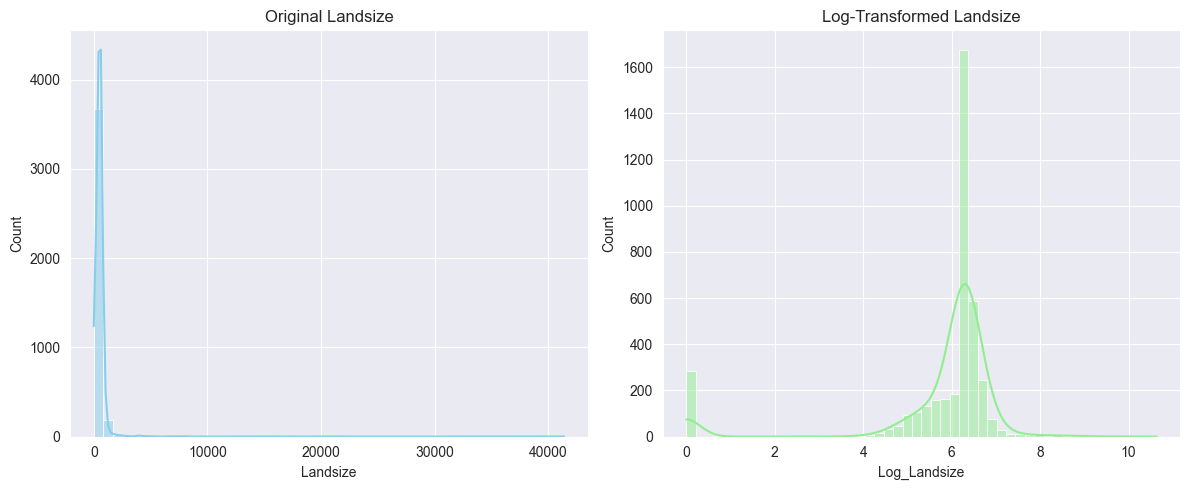

Landsize -> Skewness before: 27.88, after log-transform: -2.75



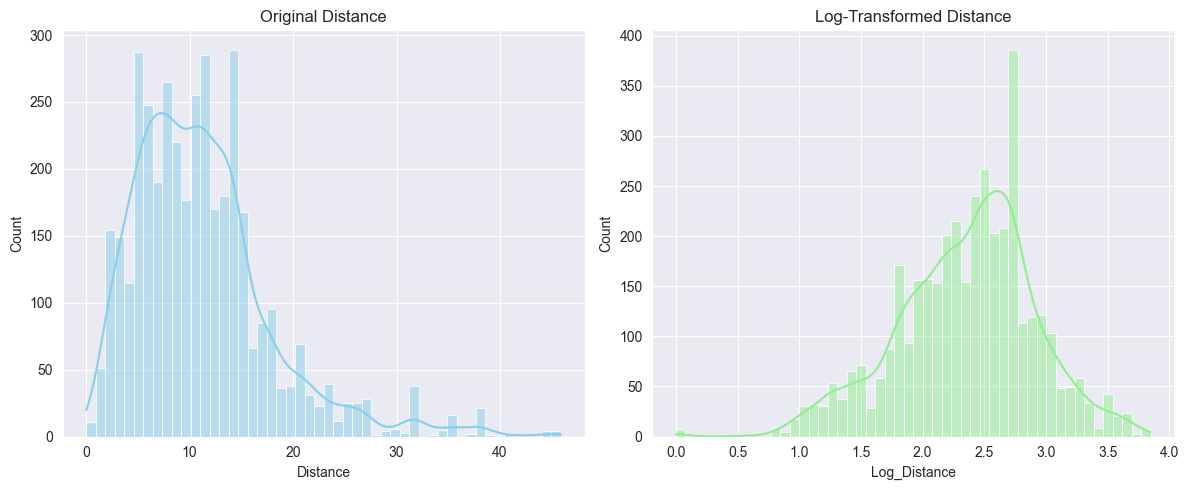

Distance -> Skewness before: 1.46, after log-transform: -0.38



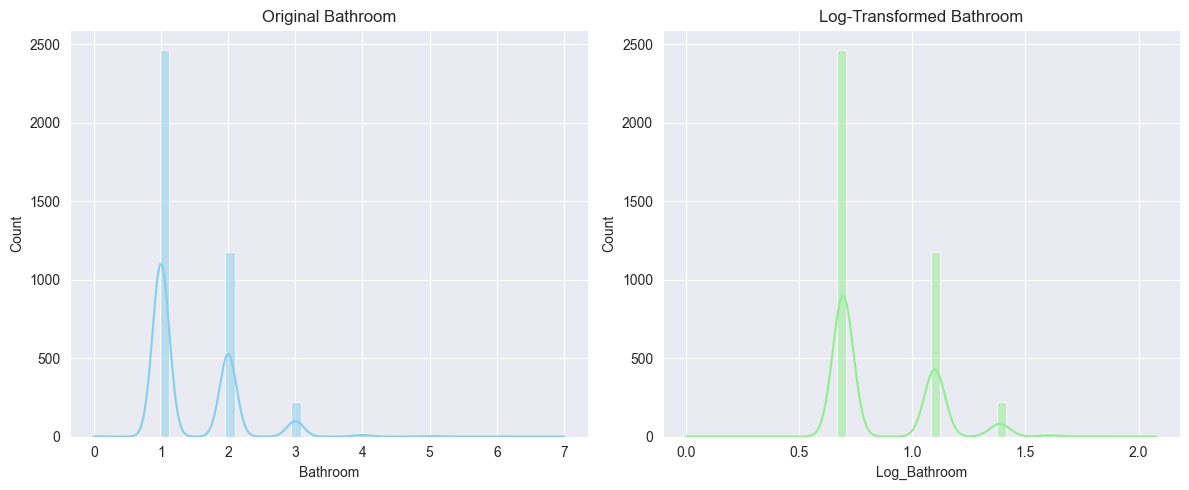

Bathroom -> Skewness before: 1.54, after log-transform: 0.95



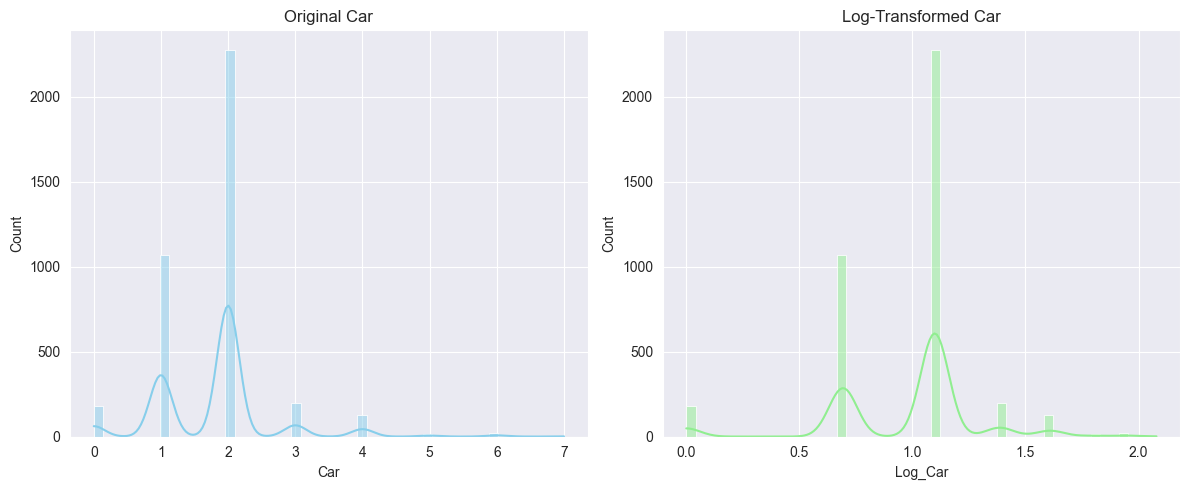

Car -> Skewness before: 1.11, after log-transform: -0.82



In [60]:

# List of columns to compare
cols_to_transform = ['Landsize', 'Distance', 'Bathroom', 'Car']

# -----------------------------
# Step 1: Plot histograms
# -----------------------------
for col in cols_to_transform:
    plt.figure(figsize=(12,5))
    
    # Original
    plt.subplot(1,2,1)
    sns.histplot(sample_df[col], bins=50, kde=True, color='skyblue')
    plt.title(f'Original {col}')
    plt.xlabel(col)
    
    # Log-transformed
    plt.subplot(1,2,2)
    sns.histplot(sample_df[f'Log_{col}'], bins=50, kde=True, color='lightgreen')
    plt.title(f'Log-Transformed {col}')
    plt.xlabel(f'Log_{col}')
    
    plt.tight_layout()
    plt.show()
    
    # Print skewness before and after
    original_skew = sample_df[col].skew()
    log_skew = sample_df[f'Log_{col}'].skew()
    print(f"{col} -> Skewness before: {original_skew:.2f}, after log-transform: {log_skew:.2f}\n")

<Axes: >

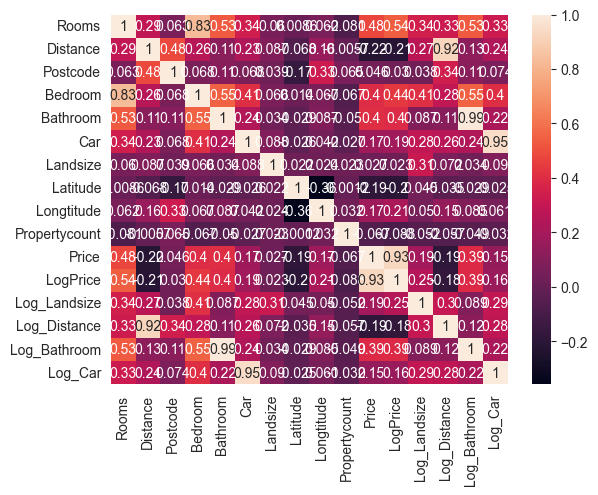

In [61]:
sns.heatmap(sample_df.corr(numeric_only=True), annot=True)

# Strong correlations between features: Rooms and Bedroom (0.83), Log_Bathroom and Bathroom (0.99), Log_Car and Car (0.95). These indicate multicollinearity, so one of each pair should be dropped or transformed for modeling.

## Predictive features for price: Rooms, Bedroom, Bathroom, and log-transformed Landsize show moderate positive correlation with LogPrice (0.25–0.54).

## Distance from CBD: negatively correlated with price (-0.21), meaning houses farther from the city center tend to be slightly cheaper.

## Weakly correlated features: Postcode (0.03) and Propertycount (-0.07) have little linear relationship with price, so they may be less informative for regression models.

Conclusions:

## Higher-income areas (proxied by Postcode) are not always more expensive; location alone does not guarantee higher prices.

## Population density (proxied by Propertycount) is not strongly correlated with house value in this dataset.

## Features to consider dropping: Rooms (due to high correlation with Bedroom) or Propertycount (due to low correlation with price).

## This analysis informs which features to keep, transform, or drop, helping improve model performance and reduce multicollinearity.

                  Rooms  Distance  Postcode   Bedroom  Bathroom       Car  \
Rooms          1.000000  0.285924  0.062505  0.834733  0.533043  0.339983   
Distance       0.285924  1.000000  0.482579  0.255360  0.114104  0.225787   
Postcode       0.062505  0.482579  1.000000  0.067776  0.107390  0.068258   
Bedroom        0.834733  0.255360  0.067776  1.000000  0.553008  0.405383   
Bathroom       0.533043  0.114104  0.107390  0.553008  1.000000  0.240063   
Car            0.339983  0.225787  0.068258  0.405383  0.240063  1.000000   
Landsize       0.060205  0.086782  0.038552  0.065517  0.034193  0.088021   
Latitude       0.008621 -0.068152 -0.165812  0.014210 -0.028690 -0.026354   
Longtitude     0.062033  0.160098  0.326338  0.067399  0.087025  0.042435   
Propertycount -0.080728 -0.005698  0.064681 -0.066721 -0.049856 -0.027295   
Price          0.478320 -0.217329  0.046289  0.396700  0.401912  0.174323   
LogPrice       0.539119 -0.213229  0.029935  0.435288  0.395359  0.187608   

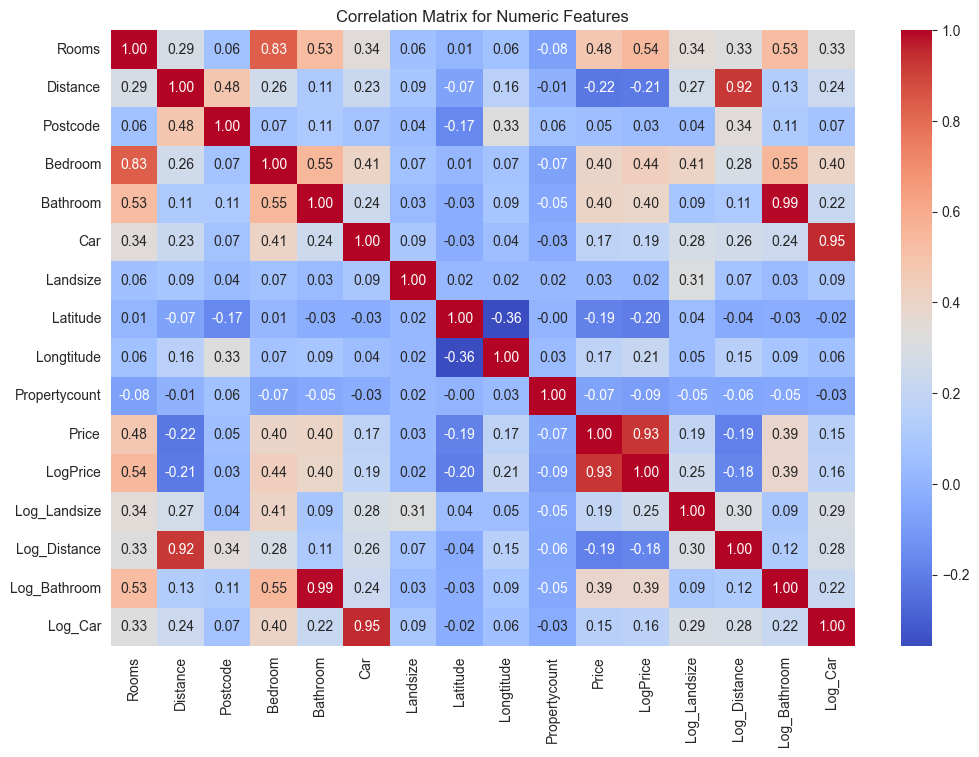

In [62]:
# Select numeric columns for correlation
numeric_cols = sample_df.select_dtypes(include='number').columns.tolist()

# Compute correlation matrix
corr_matrix = sample_df[numeric_cols].corr()

# Display correlation matrix
print(corr_matrix)

# Optional: visualize with a heatmap
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Correlation Matrix for Numeric Features")
plt.show()

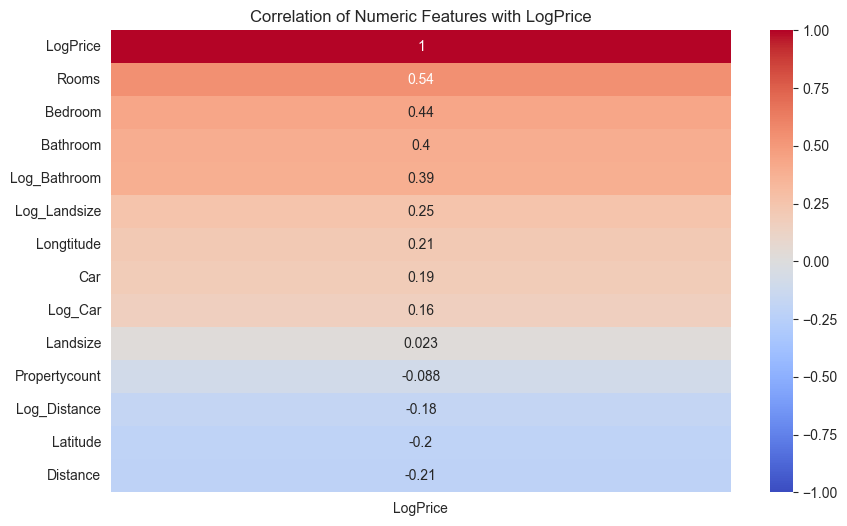

In [63]:

numeric_cols = ['Rooms','Distance','Bedroom','Bathroom','Car','Landsize',
                'Latitude','Longtitude','Propertycount','Log_Landsize',
                'Log_Distance','Log_Bathroom','Log_Car','LogPrice']

# Compute correlation matrix
corr_matrix = sample_df[numeric_cols].corr()

# Focus on correlations with LogPrice only
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix[['LogPrice']].sort_values(by='LogPrice', ascending=False), 
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation of Numeric Features with LogPrice")
plt.show()

# Categorical Features vs Targe

We examined categorical features (Type, Method, CouncilArea, Regionname) against the target (LogPrice).

Clear differences were observed:

Type: houses more expensive than townhouses, units cheapest.

Method: auction-related sales → higher prices.

CouncilArea/Regionname: inner-city & metro areas more expensive.

Conclusion: categorical variables carry predictive signal and should be kept for modeling.

Actual encoding/transformations will be handled later during feature engineering & selection.

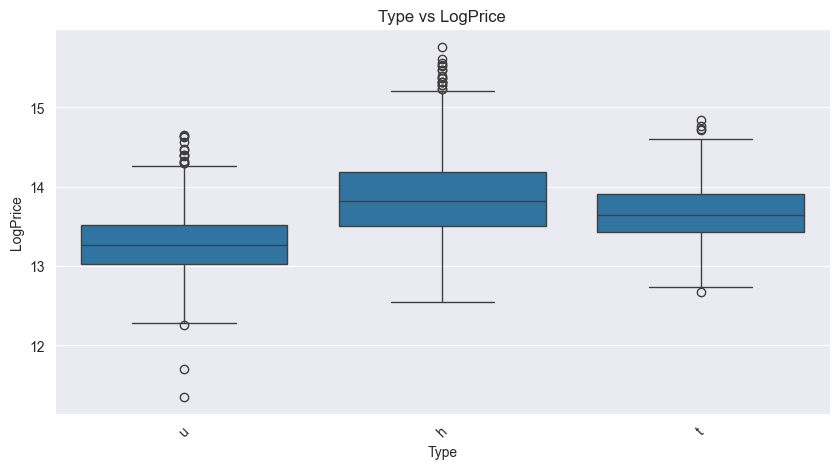

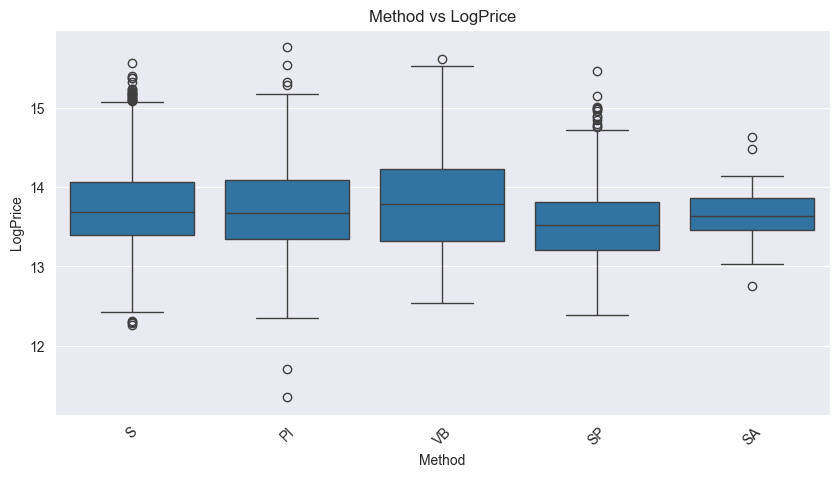

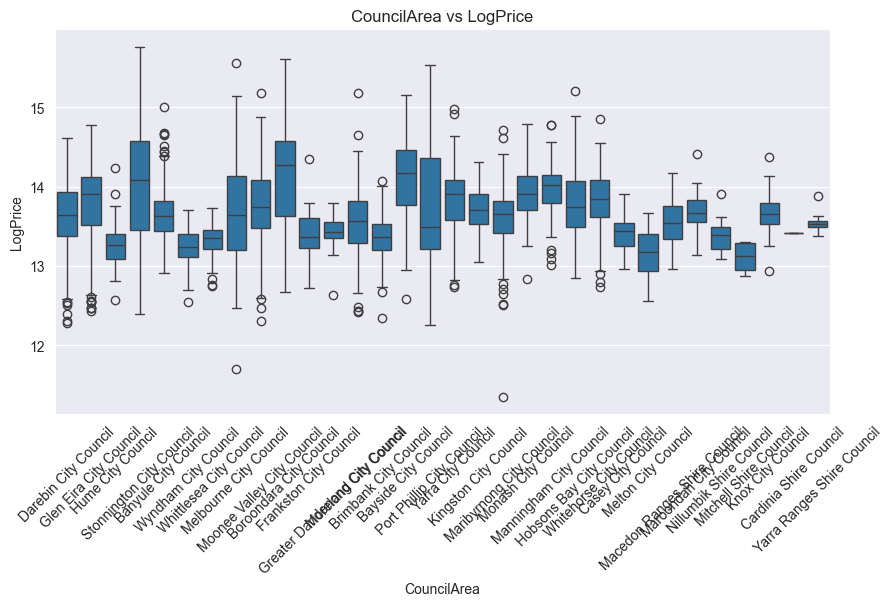

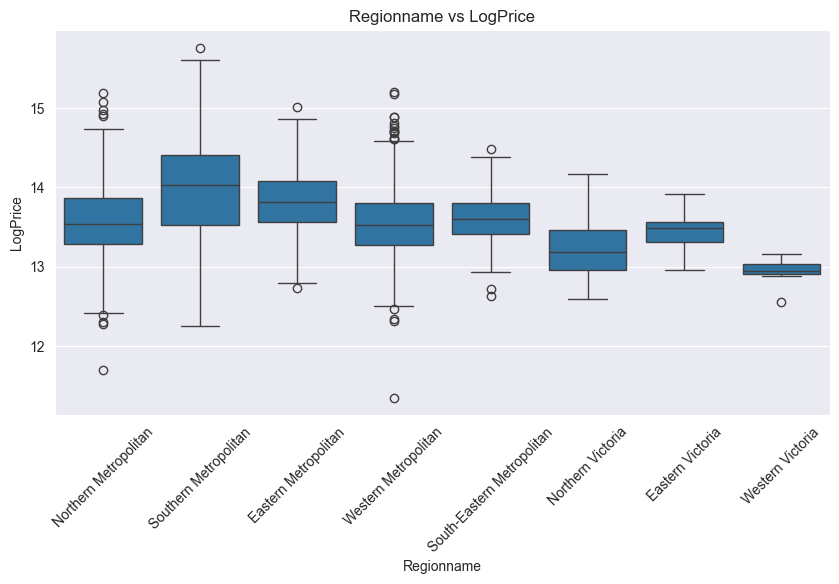

Type
h    13.866014
t    13.673219
u    13.268349
Name: LogPrice, dtype: float64
Method
VB    13.813463
S     13.735004
PI    13.725376
SA    13.667141
SP    13.563902
Name: LogPrice, dtype: float64
CouncilArea
Boroondara City Council      14.153163
Bayside City Council         14.135786
Stonnington City Council     14.036783
Manningham City Council      13.972479
Monash City Council          13.928899
Whitehorse City Council      13.837201
Yarra City Council           13.835260
Hobsons Bay City Council     13.788701
Glen Eira City Council       13.767865
Port Phillip City Council    13.724902
Name: LogPrice, dtype: float64
Regionname
Southern Metropolitan         13.964191
Eastern Metropolitan          13.822025
South-Eastern Metropolitan    13.617321
Northern Metropolitan         13.570835
Western Metropolitan          13.552632
Eastern Victoria              13.441155
Northern Victoria             13.237752
Western Victoria              12.938098
Name: LogPrice, dtype: float64


In [64]:
# Average LogPrice by categorical features
cat_features = ['Type','Method','CouncilArea','Regionname']
for col in cat_features:
    plt.figure(figsize=(10,5))
    sns.boxplot(data=sample_df, x=col, y='LogPrice')
    plt.title(f'{col} vs LogPrice')
    plt.xticks(rotation=45)
    plt.show()

# Mean LogPrice per category
for col in cat_features:
    print(sample_df.groupby(col)['LogPrice'].mean().sort_values(ascending=False).head(10))


# END OF EDA